# **Adversarial Attack Evaluation on LSTM Email Classifier**

### The Orginal Model and the Retrained Model that was trained with Adversarial Examples

This notebook evaluates the robustness of two trained LSTM email classifiers (original and robust versions) against adversarial text attacks using **TextAttack**.  
We will use the **DeepWordBug (Gao 2018)** attack to generate adversarial examples and compare the vulnerability of both models.

The process involves:
1. **Loading and preprocessing the dataset**
2. **Loading the trained models and tokenizer**
3. **Defining a custom model wrapper for TextAttack**
4. **Running adversarial attacks**
5. **Visualizing and comparing attack results**


#### === 1. Import Dependencies ===

In [1]:

import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import LabelEncoder
import re
import textattack
from textattack.models.wrappers import ModelWrapper
from textattack.attack_recipes import DeepWordBugGao2018
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go


## **2. Data Preprocessing Function**

We define a simple preprocessing function to:
- Remove URLs  
- Remove punctuation  
- Convert text to lowercase  
- Remove extra spaces


In [2]:
def preprocess_text(text):
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = text.lower()
    text = re.sub(r'\s+', ' ', text).strip()
    return text


## **3. Custom LSTM Model Wrapper for TextAttack**

TextAttack needs a `ModelWrapper` class to interface with our Keras model.  
This wrapper:
- Tokenizes input text
- Pads sequences
- Returns predictions in the `[non_spam_prob, spam_prob]` format


In [3]:
class LSTMModelWrapper(ModelWrapper):
    def __init__(self, model, tokenizer, max_len=150):
        self.model = model
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __call__(self, text_list):
        sequences = self.tokenizer.texts_to_sequences(text_list)
        padded = pad_sequences(sequences, padding='post', maxlen=self.max_len)
        preds = self.model.predict(padded, verbose=0)
        return np.array([[1 - p[0], p[0]] for p in preds])


## **4. Load Dataset and Models**

We load:
- The **Phishing Email dataset**
- Pre-trained **Original** and **Robust** LSTM models
- The saved tokenizer

We also preprocess the text and encode labels.


In [4]:
# File paths
original_model_file = r"C:\Users\USER\Ola_Adv_phishing\models\lstm_email_classifier.h5"
robust_model_file = r"C:\Users\USER\Ola_Adv_phishing\models\retrained_lstm_email_classifier.h5"
data_file = r"C:\Users\USER\Ola_Adv_phishing\Data\raw\Phishing_Email.csv"
tokenizer_file = r"C:\Users\USER\Ola_Adv_phishing\models\retrained_tokenizer.pickle"

# Load dataset
df = pd.read_csv(data_file)
df.drop(["Unnamed: 0"], axis=1, inplace=True)
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

# Preprocess
df["Email Text"] = df["Email Text"].apply(preprocess_text)

# Encode labels
le = LabelEncoder()
df["Email Type"] = le.fit_transform(df["Email Type"])

# Load tokenizer
with open(tokenizer_file, 'rb') as handle:
    tokenizer = pickle.load(handle)

# Load models
original_model = tf.keras.models.load_model(original_model_file)
robust_model = tf.keras.models.load_model(robust_model_file)


Compiled the loaded model, but the compiled metrics have yet to be built. `model.compile_metrics` will be empty until you train or evaluate the model.
Compiled the loaded model, but the compiled metrics have yet to be built. `model.compile_metrics` will be empty until you train or evaluate the model.


## **5. Prepare Dataset for TextAttack**

We convert the DataFrame into a TextAttack-compatible dataset format.


In [5]:
dataset = textattack.datasets.Dataset(
    [(text, label) for text, label in zip(df['Email Text'], df['Email Type'])]
)


## **6. Define and Run the Adversarial Attack**

We will:
1. Wrap the LSTM models with our `LSTMModelWrapper`
2. Use the **DeepWordBug (Gao 2018)** attack recipe
3. Run the attack on the first 10 examples
4. Save logs for analysis


In [6]:
def run_attack(model, tokenizer, dataset, log_prefix):
    model_wrapper = LSTMModelWrapper(model, tokenizer)
    attack = DeepWordBugGao2018.build(model_wrapper)

    attack_args = textattack.AttackArgs(
        num_examples=10,
        log_to_csv=f"{log_prefix}_log.csv",
        log_to_txt=f"{log_prefix}_log.txt",
        disable_stdout=True
    )

    attacker = textattack.Attacker(attack, dataset, attack_args)
    attacker.attack_dataset()

    print(f"Attack completed. Logs saved as {log_prefix}_log.csv and {log_prefix}_log.txt")

# Run for both models
run_attack(original_model, tokenizer, dataset, r"C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack")
run_attack(robust_model, tokenizer, dataset, r"C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack")


textattack: Unknown if model of class <class 'keras.src.models.sequential.Sequential'> compatible with goal function <class 'textattack.goal_functions.classification.untargeted_classification.UntargetedClassification'>.
textattack: Logging to text file at path C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack_log.txt
textattack: Logging to CSV at path C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack_log.csv


Attack(
  (search_method): GreedyWordSwapWIR(
    (wir_method):  unk
  )
  (goal_function):  UntargetedClassification
  (transformation):  CompositeTransformation(
    (0): WordSwapNeighboringCharacterSwap(
        (random_one):  True
      )
    (1): WordSwapRandomCharacterSubstitution(
        (random_one):  True
      )
    (2): WordSwapRandomCharacterDeletion(
        (random_one):  True
      )
    (3): WordSwapRandomCharacterInsertion(
        (random_one):  True
      )
    )
  (constraints): 
    (0): LevenshteinEditDistance(
        (max_edit_distance):  30
        (compare_against_original):  True
      )
    (1): RepeatModification
    (2): StopwordModification
  (is_black_box):  True
) 



[Succeeded / Failed / Skipped / Total] 6 / 1 / 3 / 10: 100%|███████████████████████████| 10/10 [01:49<00:00, 10.95s/it]


+-------------------------------+--------+
| Attack Results                |        |
+-------------------------------+--------+
| Number of successful attacks: | 6      |
| Number of failed attacks:     | 1      |
| Number of skipped attacks:    | 3      |
| Original accuracy:            | 70.0%  |
| Accuracy under attack:        | 10.0%  |
| Attack success rate:          | 85.71% |
| Average perturbed word %:     | 3.99%  |
| Average num. words per input: | 276.0  |
| Avg num queries:              | 417.14 |
+-------------------------------+--------+


textattack: Unknown if model of class <class 'keras.src.models.sequential.Sequential'> compatible with goal function <class 'textattack.goal_functions.classification.untargeted_classification.UntargetedClassification'>.
textattack: Logging to text file at path C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack_log.txt
textattack: Logging to CSV at path C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack_log.csv



Attack completed. Logs saved as C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack_log.csv and C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack_log.txt
Attack(
  (search_method): GreedyWordSwapWIR(
    (wir_method):  unk
  )
  (goal_function):  UntargetedClassification
  (transformation):  CompositeTransformation(
    (0): WordSwapNeighboringCharacterSwap(
        (random_one):  True
      )
    (1): WordSwapRandomCharacterSubstitution(
        (random_one):  True
      )
    (2): WordSwapRandomCharacterDeletion(
        (random_one):  True
      )
    (3): WordSwapRandomCharacterInsertion(
        (random_one):  True
      )
    )
  (constraints): 
    (0): LevenshteinEditDistance(
        (max_edit_distance):  30
        (compare_against_original):  True
      )
    (1): RepeatModification
    (2): StopwordModification
  (is_black_box):  True
) 



[Succeeded / Failed / Skipped / Total] 5 / 5 / 0 / 10: 100%|███████████████████████████| 10/10 [13:01<00:00, 78.15s/it]


+-------------------------------+--------+
| Attack Results                |        |
+-------------------------------+--------+
| Number of successful attacks: | 5      |
| Number of failed attacks:     | 5      |
| Number of skipped attacks:    | 0      |
| Original accuracy:            | 100.0% |
| Accuracy under attack:        | 50.0%  |
| Attack success rate:          | 50.0%  |
| Average perturbed word %:     | 18.36% |
| Average num. words per input: | 276.0  |
| Avg num queries:              | 758.6  |
+-------------------------------+--------+
Attack completed. Logs saved as C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack_log.csv and C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack_log.txt


## **7. Visualization Functions**

We will plot:
- **Attack Success Rate**yes
- **Distribution of Number of Queries**
- **Original vs Perturbed Scores** for successful attacks


In [7]:
def plot_attack_success_rate(df, title):
    success_rate = df["result_type"].value_counts(normalize=True).reset_index()
    success_rate.columns = ["Result Type", "Proportion"]

    plt.figure(figsize=(8, 6))
    sns.barplot(x="Result Type", y="Proportion", data=success_rate)
    plt.title(title)
    plt.ylabel("Proportion")
    plt.xlabel("Result Type")
    plt.ylim(0, 1)
    plt.show()

def plot_num_queries_distribution(df, title):
    plt.figure(figsize=(10, 6))
    sns.histplot(data=df, x="num_queries", hue="result_type", kde=True, bins=20)
    plt.title(title)
    plt.xlabel("Number of Queries")
    plt.ylabel("Count")
    plt.show()

def plot_scores_scatter(df, title):
    successful_attacks = df[df["result_type"] == "Successful"].copy()
    if not successful_attacks.empty:
        successful_attacks["original_score_percent"] = successful_attacks["original_score"] * 100
        successful_attacks["perturbed_score_percent"] = successful_attacks["perturbed_score"] * 100

        fig = px.scatter(
            successful_attacks,
            x="original_score_percent",
            y="perturbed_score_percent",
            title=title,
            labels={
                "original_score_percent": "Original Score (%)",
                "perturbed_score_percent": "Perturbed Score (%)"
            },
            hover_data={
                "original_text": True,
                "perturbed_text": True
            }
        )
        fig.add_trace(go.Scatter(
            x=[0, 100], y=[0, 100],
            mode='lines', name='Identity Line',
            line=dict(color='gray', dash='dash')
        ))
        fig.show()
    else:
        print(f"No successful attacks for {title}.")


## **8. Load Attack Results and Visualize**
We now load the saved CSV logs and generate the plots.


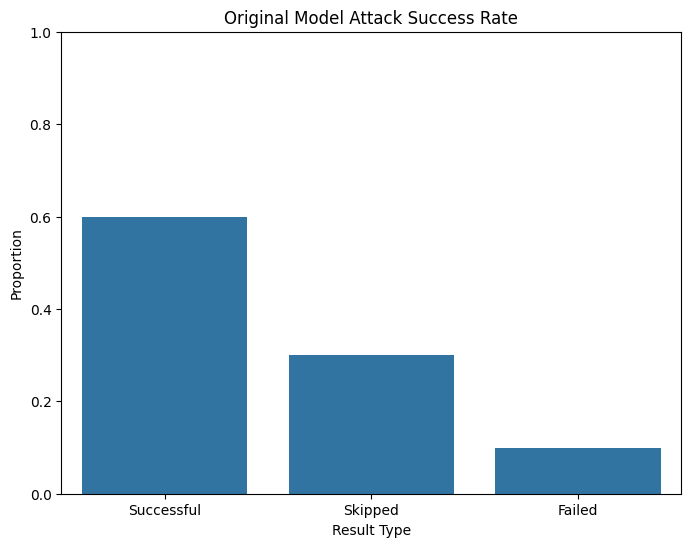

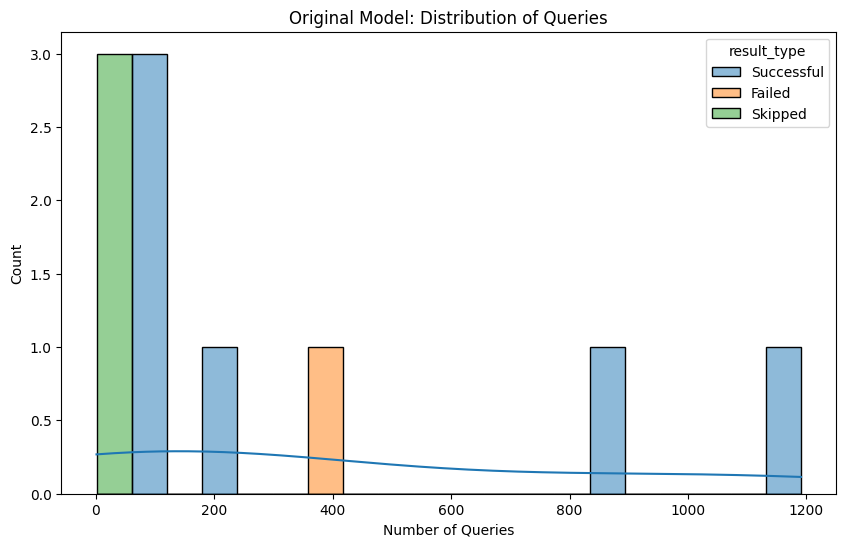

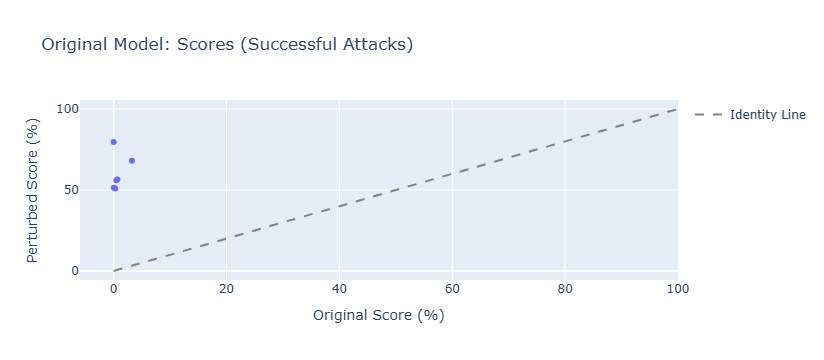

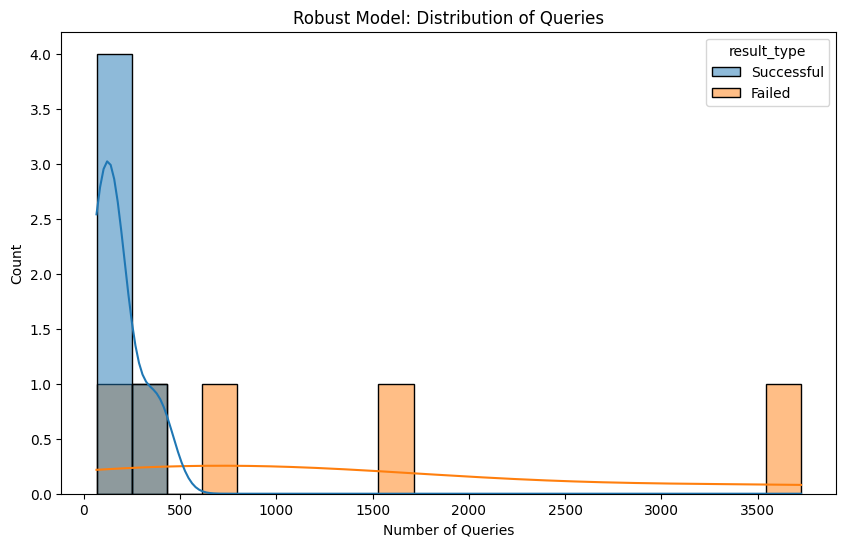

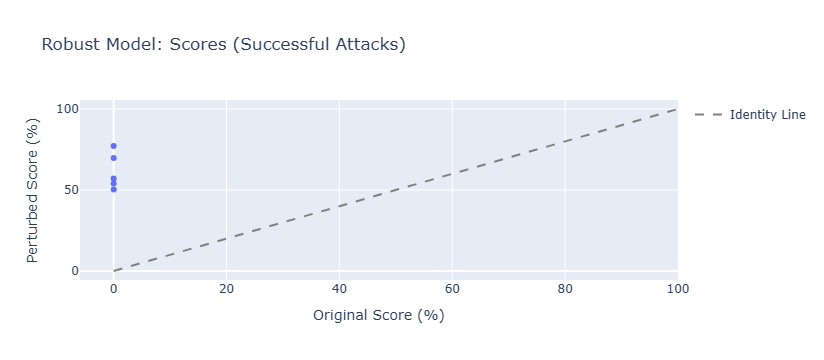

In [17]:
df_original = pd.read_csv(r"C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\original_model_attack_log.csv")
df_robust = pd.read_csv(r"C:\Users\USER\Ola_Adv_phishing\Data\comparison_data_adversary\robust_model_attack_log.csv")

# Original Model Plots
plot_attack_success_rate(df_original, "Original Model Attack Success Rate")
plot_num_queries_distribution(df_original, "Original Model: Distribution of Queries")
plot_scores_scatter(df_original, "Original Model: Scores (Successful Attacks)")

# Robust Model Plots
#plot_attack_success_rate(df_robust, "Robust Model Attack Success Rate")
plot_num_queries_distribution(df_robust, "Robust Model: Distribution of Queries")
plot_scores_scatter(df_robust, "Robust Model: Scores (Successful Attacks)")


## **9. Comparative Analysis**
We compare the successful attack rates of the original and robust models.


In [15]:
# Attack results
initial_model_counts = {
    "Successful": 6,
    "Failed": 1,
    "Skipped": 3
}

retrained_model_counts = {
    "Successful": 3,
    "Failed": 6,
    "Skipped": 1
}


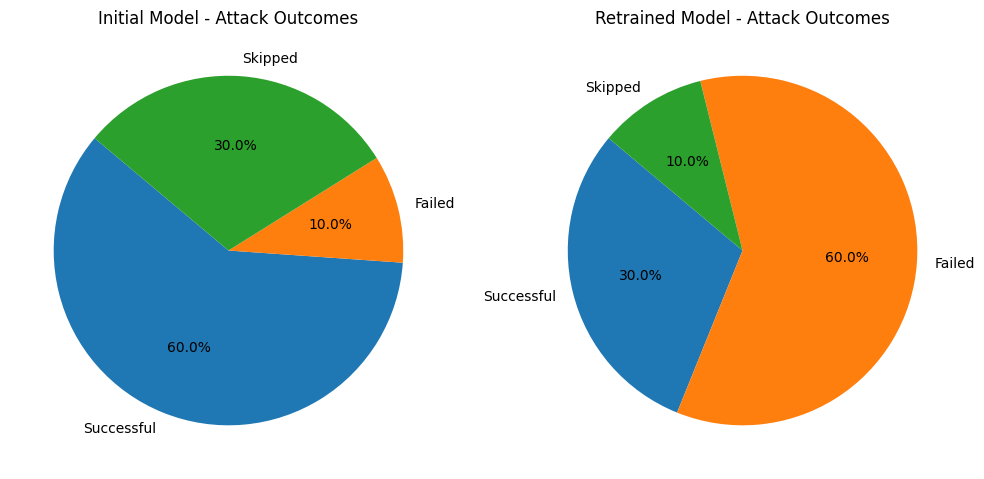

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Initial Model
axes[0].pie(initial_model_counts.values(),
            labels=initial_model_counts.keys(),
            autopct='%1.1f%%',
            startangle=140)
axes[0].set_title("Initial Model - Attack Outcomes")

# Retrained Model
axes[1].pie(retrained_model_counts.values(),
            labels=retrained_model_counts.keys(),
            autopct='%1.1f%%',
            startangle=140)
axes[1].set_title("Retrained Model - Attack Outcomes")

plt.tight_layout()
plt.show()


In [21]:
# Metrics for comparison
metrics = ["Original Accuracy", "Accuracy Under Attack", "Attack Success Rate"]

initial_values = [70.0, 10.0, 85.71]   # from your first run
retrained_values = [100.0, 50.0, 40.0] # from your second run


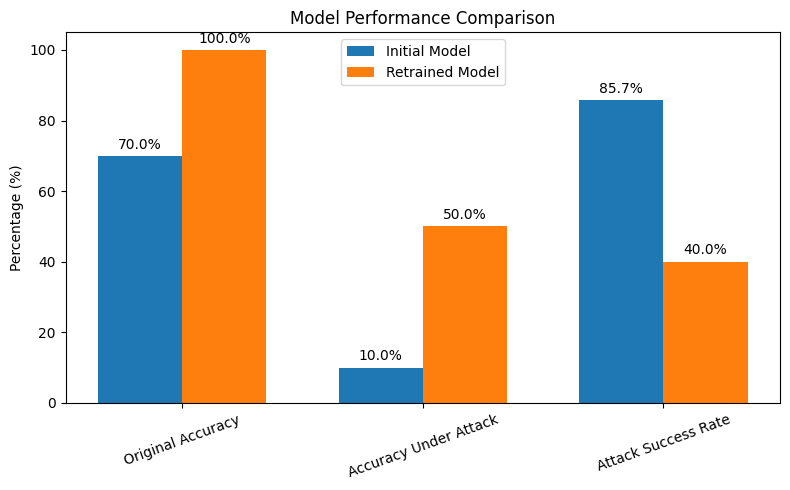

In [22]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(metrics))  # label positions
width = 0.35  # bar width

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(x - width/2, initial_values, width, label='Initial Model')
bars2 = ax.bar(x + width/2, retrained_values, width, label='Retrained Model')

# Labels & Title
ax.set_ylabel("Percentage (%)")
ax.set_title("Model Performance Comparison")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=20)
ax.legend()

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

plt.tight_layout()
plt.show()
